# 07a. Case study: the January 2012 Pacific Northwest storm: regional series

## Purpose

How do the initialization approaches represent the 16-20 January 2012 Pacific Northwest storm in the Dec 2011 starts, under prescribed observed SST? The storm brought heavy snow inland and in the Cascades, record rain and flooding in western Oregon (an atmospheric-river, "Pineapple Express" episode) and hurricane-force gusts on the coast. This notebook does the first steps: the simulation coverage, regional daily temperature and precipitation of every member against the observations on a fixed observed window, member event metrics, event maps, and the large-scale storm environment (sea-level pressure, 500-hPa height, integrated vapour transport) before and during the event.

At leads of 2-5 weeks the question is whether an experiment produces **a favourable regional circulation and cold-wet environment during the observed period**, not whether it reproduces the exact cyclone track; the environment maps keep the two apart.

## Design: three questions (as notebook 06)

| Question | Experiments |
|---|---|
| Q1. Does event-informed initialization improve the event? | HYB_BASE and DA_COUPLED against CLIM_BASE (free-running-reference baseline) |
| Q2. Do the two initialization approaches differ? | DA_COUPLED against HYB_BASE |
| Q3. What roles do the component states and their consistency play? | DA_ATM (DART atmosphere, reference land) and DA_LND (ERA5 atmosphere, DART land) |

`primary` holds the Q1/Q2 experiments. All are 20-member ensembles; the series and maps pool the 4 starts (80 members); the metrics keep each start (one marker per start).

**Caveat (2026-11-06):** HYB_BASE and DA_LND started from an ERA5 atmosphere without the radiative tracers, aerosols and chemistry (6-7 K too cold over land for weeks); they are dashed and marked "IC defect" (`ic_defect`) until rerun from the completed initial files. Q2 and the DA_LND part of Q3 wait for those reruns.

## Event definition

Fixed observed window `event_window` = 16-20 Jan 2012 (antecedent period from the start to 15 Jan; aftermath 21-23 Jan). Regions (land, 1-degree): `WEST_WA_OR` (42-49N, 124.5-121.5W: coast, Puget-Willamette lowlands and the western Cascades) and `INLAND_PNW` (42-49N, 121.5-111W: east of the Cascades to Idaho). Observations: ERA5 daily-mean 2-m temperature and GPCP V3.3 daily precipitation (1 degree); no gridded snow observation is used (the archive's SWE products are monthly and mask mountains), so model snow water (H2OSNO) is shown without observations.

**The 07a-07d series** (January 2012 Pacific Northwest storm; each notebook reads the data it needs, computes, saves, then plots): `07a` regional series; `07b` member storm metrics; `07c` event maps; `07d` storm environment. Settings: `WinterStormSettings` in `configs/hind_lead_eval_cases.py`; products: `util/winter_storm_workflow.py`; methods: `util/winter_storm_case.py`. Design and event definition: `07a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/winter_storm_2012/`: `observed_fields.nc`, `box_{map,env}_<CONFIG>_DJF_<VAR>.nc` (shared inputs of the series), `coverage.csv`, `storm_series.nc`; figures `storm_series_{primary,all}_<BIAS>.png` in `figure/hind_lead_eval/winter_storm_2012/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the WinterStormSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"max_members": 4}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import WinterStormSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.winter_storm_workflow import WinterStormCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = WinterStormCase(WinterStormSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012
[IC DEFECT] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both TREFHT climatologies (for the `amip` bias treatment and the temperature anomaly maps) and the regional masks (`observed_fields.nc`); the observed metrics and the simulation coverage of the window. Then the daily TREFHT, PRECT and H2OSNO of every member on the map box (`box_map_<CONFIG>_DJF_<VAR>.nc`), the members of all starts pooled on calendar days.

In [4]:
obs = case.obs
display(obs.metrics.round(2), obs.coverage)
series = case.series

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/observed_fields.nc
{'WEST_WA_OR': 24, 'INLAND_PNW': 77} land points
[EVENT] 2012-01-16 to 2012-01-20; observed WEST_WA_OR precipitation peak 2012-01-19


,event_precip_mm,max_daily_precip_mm,peak_precip_date_error_days,event_mean_t_c,event_min_t_c,precip_freezing_days_mm,precip_near_freezing_days_mm,window_days_covered
region,,,,,,,,
WEST_WA_OR,97.89,48.14,0,0.26,-3.34,3.12,31.10,5
INLAND_PNW,21.72,10.43,2,-6.36,-9.64,21.72,21.72,5


,init,last_day,lead_at_onset,lead_at_end,window_covered
0,2011-12-16,2012-02-14,32,36,full
1,2011-12-21,2012-02-19,27,31,full
2,2011-12-26,2012-02-24,22,26,full
3,2011-12-31,2012-02-29,17,21,full


[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] CLIM_BASE H2OSNO: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] HYB_BASE H2OSNO: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_COUPLED H2OSNO: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_ATM H2OSNO: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] DA_LND H2OSNO: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


## 5. Process and save

The regional daily series of every configuration, region, bias treatment and pooled member, with the observations (`storm_series.nc`), and the coverage table (`coverage.csv`).

In [5]:
write_table(obs.coverage, case.data_dir / "coverage.csv")
ds = case.series_dataset()
write_dataset(ds, case.data_dir / "storm_series.nc")
print(dict(ds.sizes))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/coverage.csv


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/storm_series.nc
{'time': 76, 'config': 5, 'region': 2, 'bias': 2, 'member_index': 80}


## 6. Plot and show

Regional series, the Q1/Q2 set (`primary`), then all five configurations.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_series_primary_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_series_all_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_series_primary_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_series_all_amip.png


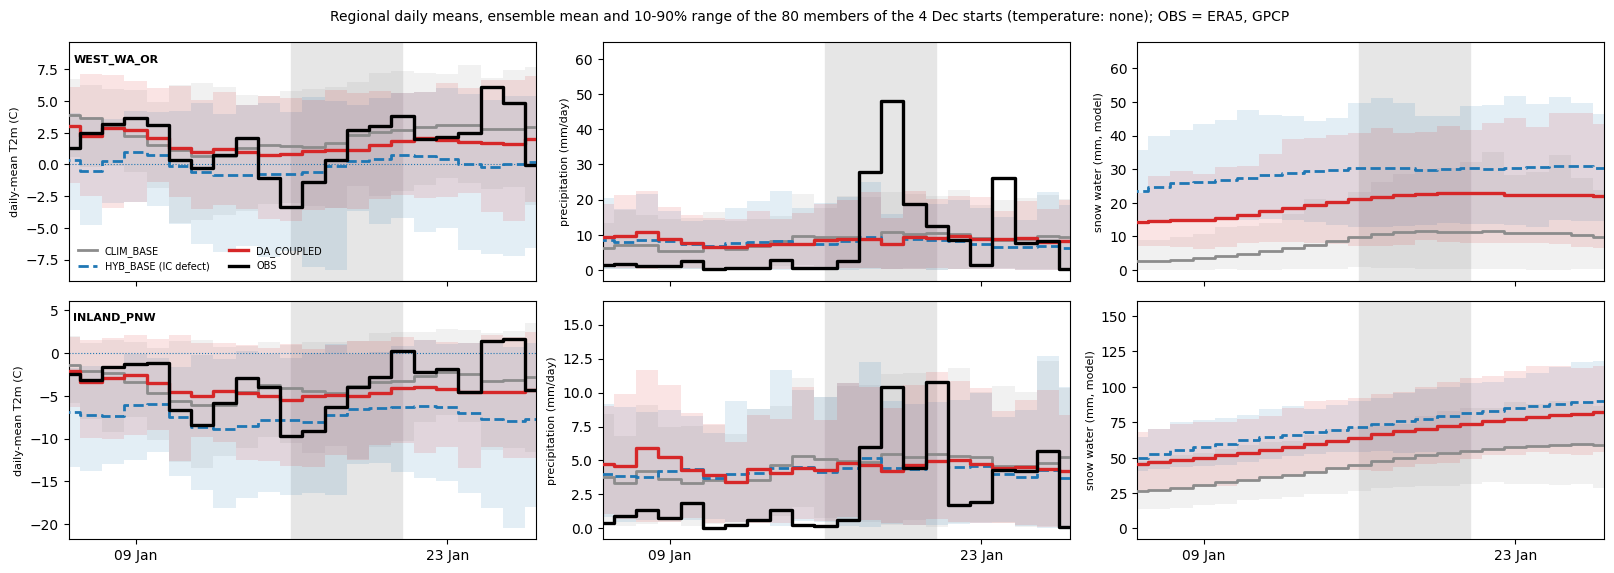

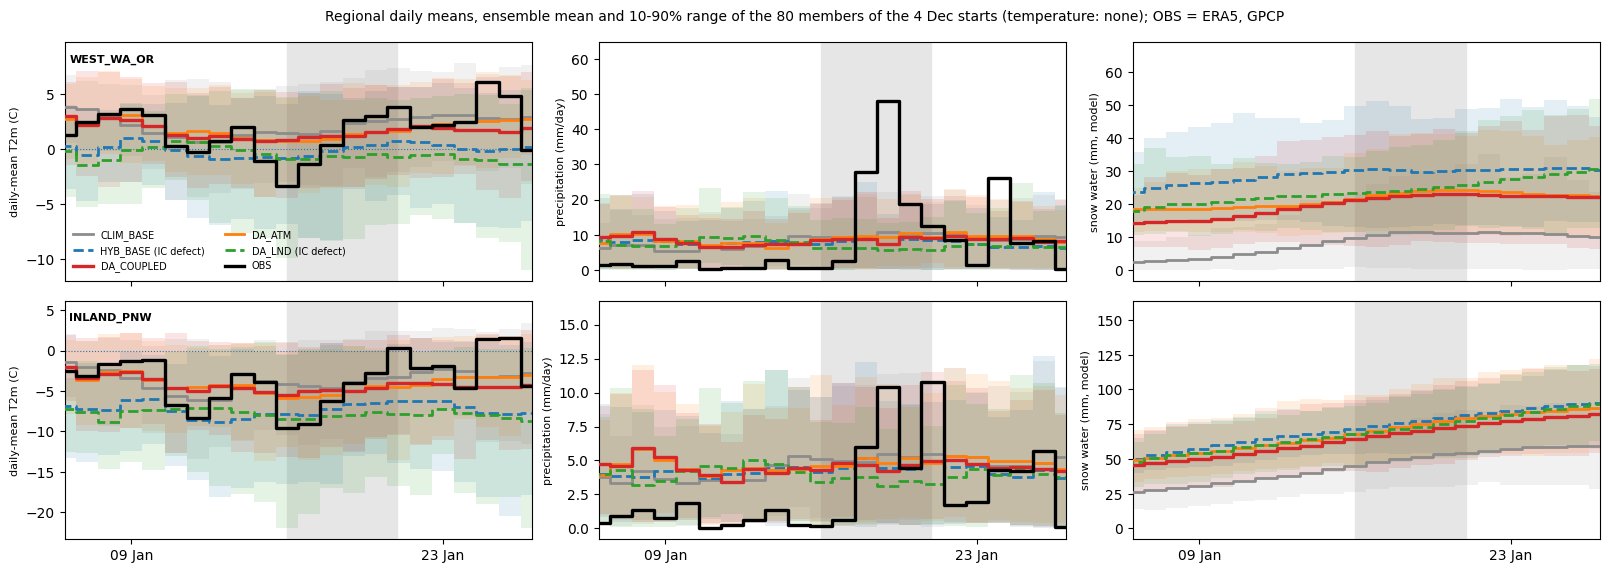

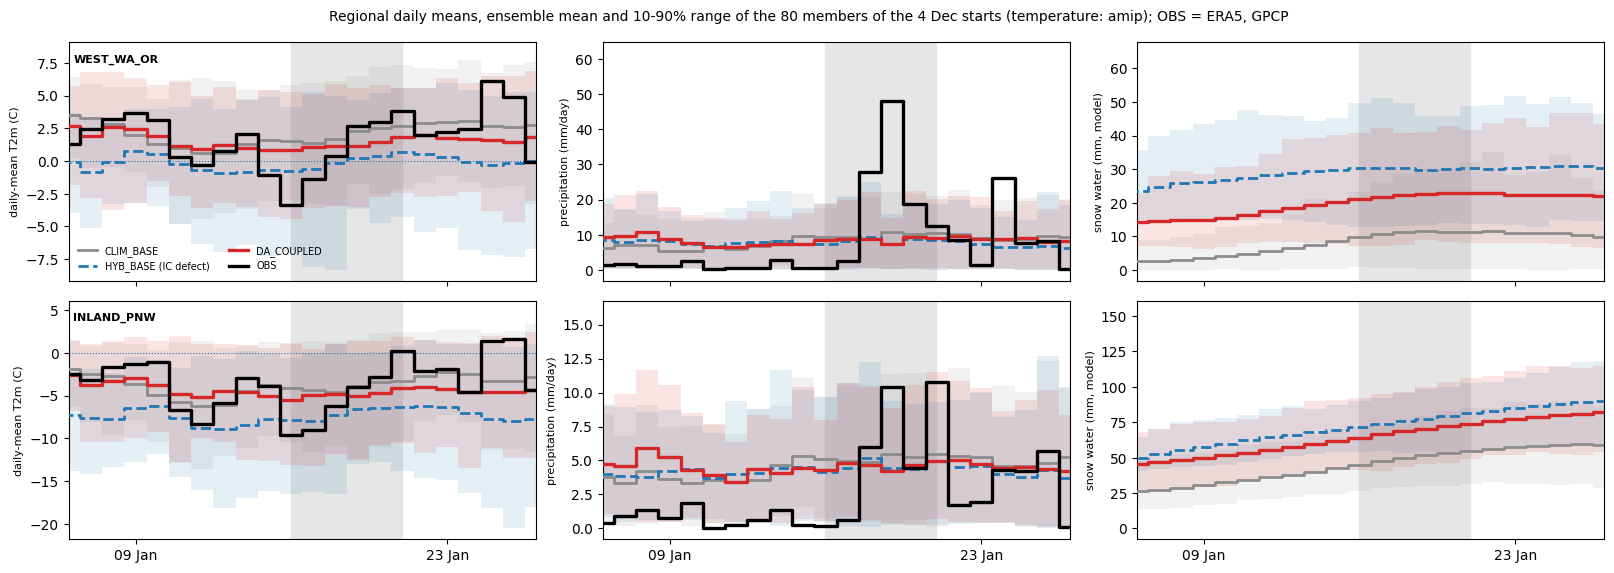

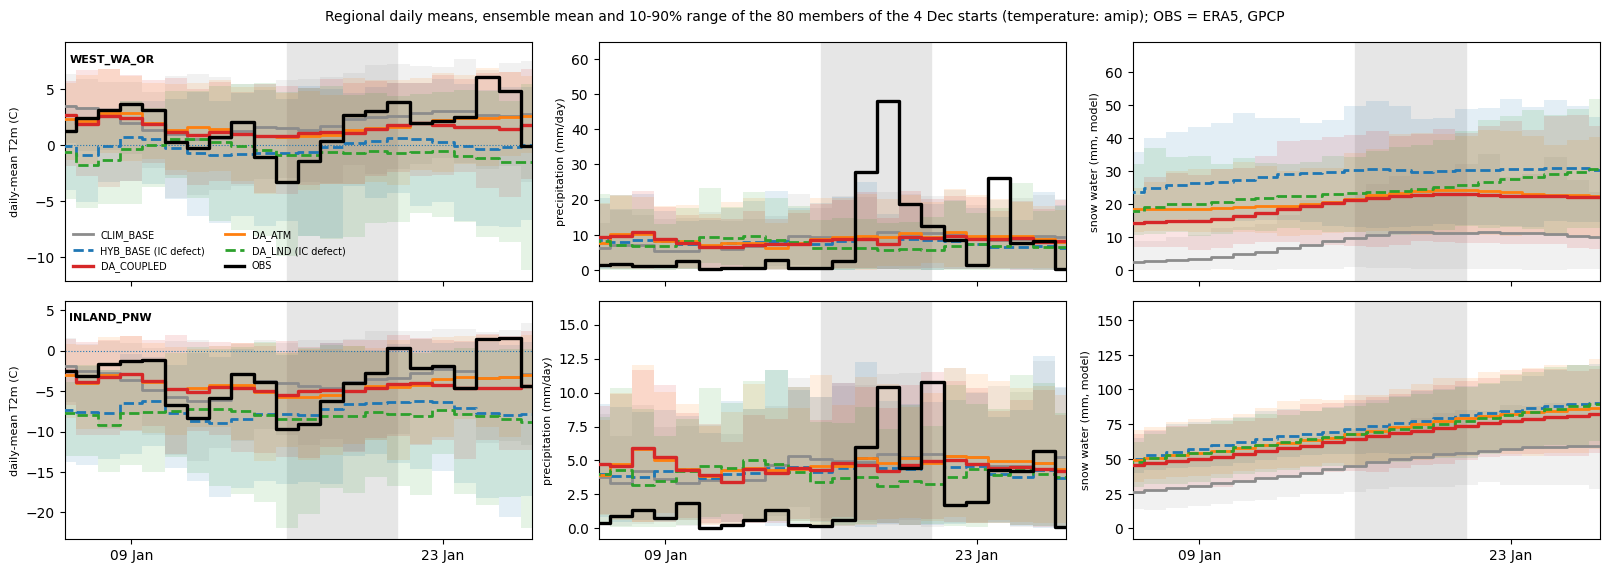

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.winter_storm_case import plot_region_series
from util.winter_storm_workflow import SERIES_VARS, SERIES_YLABELS

lo, hi = int(cfg.spread[0] * 100), int(cfg.spread[1] * 100)
for b in cfg.biases:
    for tag, cfgs in (("primary", list(cfg.primary)), ("all", list(cfg.configs))):
        panels = {r: {v: {c: series[b, r, c][v] for c in cfgs} for v in SERIES_VARS} for r in case.region_names}
        save(plot_region_series(panels, obs.reg, cfg.event_window, STYLE_MAP, list(cfg.ic_defect), ylabels=SERIES_YLABELS,
                                spread=cfg.spread, xlim=cfg.series_xlim,
                                title=f"Regional daily means, ensemble mean and {lo}-{hi}% range of the "
                                      f"{len(case.inits) * len(case.members[cfg.configs[0]])} members "
                                      f"of the {len(case.inits)} Dec starts (temperature: {b}); OBS = ERA5, GPCP"),
             f"storm_series_{tag}_{b}.png")